### Importing packages 

In [37]:
import numpy as np
from objective import make_weighted_quadratic
import matplotlib.pyplot as plt
import pandas as pd

### Creating Random Search function

In [38]:

def random_search(objective, budget=400, seed=0):
    """
    Uniform random search over [-1, 1]^20.

    Parameters
    ----------
    objective : callable
        Objective returned by make_weighted_quadratic().
    budget : int
        Total number of objective evaluations.
    seed : int
        Random seed controlling the search, independent of
        the objective's seed.

    Returns
    -------
    best_x : ndarray
        Best candidate found.
    history : ndarray
        Best objective value after each evaluation.
    """
    if budget < 1:
        raise ValueError("budget must be at least 1")

    rng = np.random.default_rng(seed)

    best_x = None
    best_value = np.inf
    history = np.empty(budget)

    for i in range(budget):
        # Sample a candidate uniformly from the full 20D domain.
        x = rng.uniform(-1.0, 1.0, size=20)

        # Evaluate the objective exactly once.
        value = objective(x)

        if value < best_value:
            best_value = value
            best_x = x.copy()

        history[i] = best_value

    return best_x, history


### Running the Experiment 

In [39]:
effective_dims = [2, 5, 10, 15, 20]
objective_seeds = [0, 1, 2]
n_runs = 3
orientations = [False, True]
budget = 400

results = {}

for d in effective_dims:
    for objective_seed in objective_seeds:
        for replicate in range(n_runs):
            for rotated in orientations:

                objective = make_weighted_quadratic(
                    d=d,
                    seed=objective_seed,
                    rotated=rotated,
                )

                search_seed = 1000 * objective_seed + replicate

                _, history = random_search(
                    objective=objective,
                    budget=budget,
                    seed=search_seed,
                )

                results[(d, objective_seed, replicate, rotated)] = history

print(results[(5, 0, 0, True)].shape)

(400,)


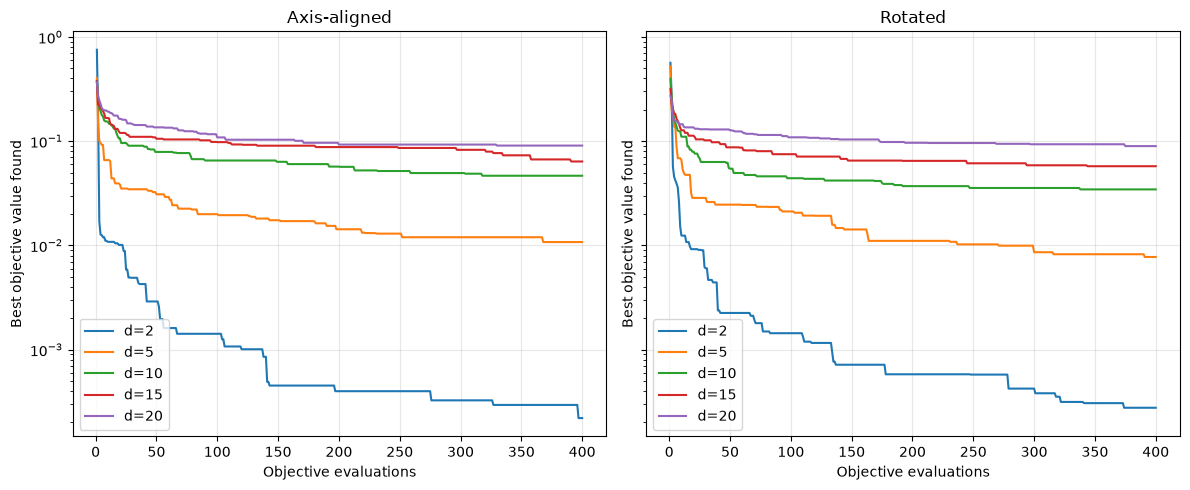

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, rotated in zip(axes, [False, True]):
    for d in effective_dims:

        # Collect all histories for this dimension and orientation
        histories = np.array([
            results[(d, objective_seed, replicate, rotated)]
            for objective_seed in objective_seeds
            for replicate in range(n_runs)
        ])

        mean_history = histories.mean(axis=0)

        ax.plot(
            np.arange(1, budget + 1),
            mean_history,
            label=f"d={d}",
        )
    ax.set_yscale("log")  # Logarithmic y-axis
    ax.set_title("Rotated" if rotated else "Axis-aligned")
    ax.set_xlabel("Objective evaluations")
    ax.set_ylabel("Best objective value found")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
rows = []

for d in effective_dims:
    for rotated in orientations:
        final_values = [
            results[(d, objective_seed, replicate, rotated)][-1]
            for objective_seed in objective_seeds
            for replicate in range(n_runs)
        ]

        rows.append({
            "Effective dimension": d,
            "Orientation": "Rotated" if rotated else "Axis-aligned",
            "Mean final best": np.mean(final_values),
            "Std dev": np.std(final_values, ddof=1),
            "Median final best": np.median(final_values),
        })

summary_table = pd.DataFrame(rows)

print(summary_table.round(6).to_string(index=False))

 Effective dimension  Orientation  Mean final best  Std dev  Median final best
                   2 Axis-aligned         0.000220 0.000231           0.000099
                   2      Rotated         0.000277 0.000417           0.000093
                   5 Axis-aligned         0.010766 0.005090           0.009517
                   5      Rotated         0.007742 0.002728           0.008013
                  10 Axis-aligned         0.046598 0.007722           0.046652
                  10      Rotated         0.034459 0.013313           0.035679
                  15 Axis-aligned         0.063845 0.017704           0.064542
                  15      Rotated         0.057508 0.017762           0.066217
                  20 Axis-aligned         0.090738 0.018467           0.097693
                  20      Rotated         0.089687 0.020668           0.098768
